<center><image src="https://drive.google.com/uc?id=1n3G4TdK_u6PQHcLrxB_A0HijNdigXmUH">

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h3 style="text-align: center;"><b>Домашнее задание. Сегментация изображений</b></h3>


В этом задании вам предстоит решить задачу сегментации медицинских снимков. Домашнее задание можно разделить на следующие части:

* Построй свой первый бейзлайн! [6]
  * BCE Loss [2]
  * SegNet [2]
  * Train [1]
  * Test [1]
* Мир других лоссов! [2]
  * Dice Loss [1]
  * Focal Loss [1]
  * BONUS: лосс из статьи [5]
* Новая модель! [2]
  * UNet [2]


**Максимальный балл:** 10 баллов.

Также для студентов желающих еще более углубиться в задачу предлагается решить бонусное задание, которое даст дополнительные 5 баллов. BONUS задание необязательное.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output

import torch
from torch.utils.data import DataLoader
import torch.nn.functional as F
import torch.nn as nn

from skimage.io import imread
import os
import random

from skimage.transform import resize

In [ ]:
# для детерминированности
SEED = 42

torch.manual_seed(SEED)

torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

np.random.seed(SEED)
random.seed(SEED)

# Шаг 1. Загрузка и подготовка данных

1. Для начала мы скачаем датасет: [ADDI project](https://www.fc.up.pt/addi/ph2%20database.html).

<table><tr><td>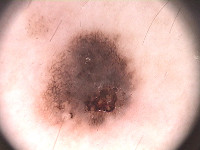</td><td>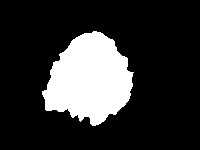</td></tr></table>

2. Разархивируем .rar файл.
3. Обратите внимание, что папка  `PH2 Dataset images` должна лежать там же где и ipynb notebook.

Это фотографии двух типов **поражений кожи:** меланома и родинки.
В данном задании мы не будем заниматься их классификацией, а будем **сегментировать** их.

In [ ]:
!gdown 1T_RPkPP0jeWwK8L1UrmBw8V30eD7v6Ql

Downloading...
From (original): https://drive.google.com/uc?id=1T_RPkPP0jeWwK8L1UrmBw8V30eD7v6Ql
From (redirected): https://drive.google.com/uc?id=1T_RPkPP0jeWwK8L1UrmBw8V30eD7v6Ql&confirm=t&uuid=7d5bee24-d298-411d-9e18-147d018a982a
To: /content/PH2Dataset.rar
100% 162M/162M [00:01<00:00, 120MB/s]


In [ ]:
get_ipython().system_raw("unrar x PH2Dataset.rar")

Стуктура датасета у нас следующая:

    IMD_002/
        IMD002_Dermoscopic_Image/
            IMD002.bmp
        IMD002_lesion/
            IMD002_lesion.bmp
        IMD002_roi/
            ...
    IMD_003/
        ...
        ...

 Здесь `X.bmp` — изображение, которое нужно сегментировать, `X_lesion.bmp` — результат сегментации.

Для загрузки датасета можно использовать skimage: [`skimage.io.imread()`](https://scikit-image.org/docs/dev/api/skimage.io.html)

In [ ]:
images = []
lesions = []

root = 'PH2Dataset'

for root, dirs, files in os.walk(os.path.join(root, 'PH2 Dataset images')):
    if root.endswith('_Dermoscopic_Image'):
        images.append(imread(os.path.join(root, files[0])))
    if root.endswith('_lesion'):
        lesions.append(imread(os.path.join(root, files[0])))

Изображения имеют разные размеры. Давайте изменим их размер на $256\times256 $ пикселей. Для изменения размера изображений можно использовать [`skimage.transform.resize()`](https://scikit-image.org/docs/dev/api/skimage.transform.html#skimage.transform.resize).
Эта функция также автоматически нормализует изображения в диапазоне $[0,1]$.


In [ ]:
size = (256, 256)
X = [resize(x, size, mode='constant', anti_aliasing=True) for x in images]
Y = [resize(y, size, mode='constant', anti_aliasing=False) > 0.5 for y in lesions]

In [ ]:
X = np.array(X, np.float32)
Y = np.array(Y, np.float32)
print(f'Loaded {len(X)} images')

Loaded 200 images


Чтобы убедиться, что все корректно, мы нарисуем несколько изображений

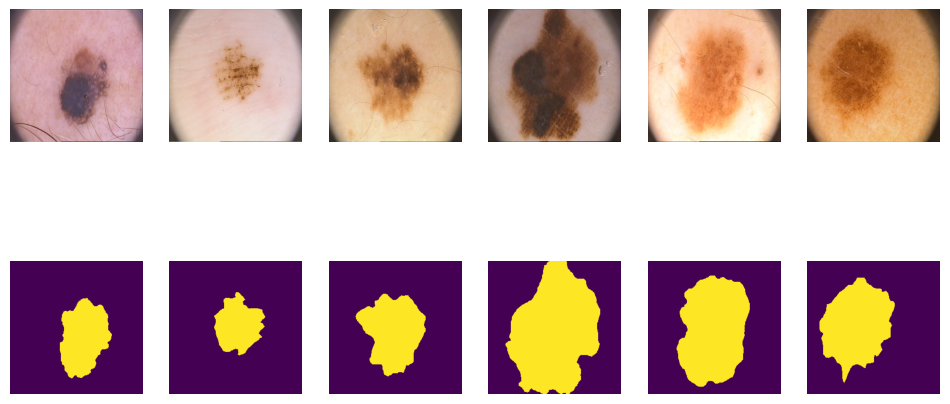

In [ ]:
plt.figure(figsize=(12, 6))
for i in range(6):
    plt.subplot(2, 6, i+1)
    plt.axis("off")
    plt.imshow(X[i])

    plt.subplot(2, 6, i+7)
    plt.axis("off")
    plt.imshow(Y[i])
plt.show();

Разделим наши 200 картинок на 100/50/50
 для обучения, валидации и теста соответственно

In [ ]:
ix = np.random.choice(len(X), len(X), False)
tr, val, ts = np.split(ix, [100, 150])

In [ ]:
print(len(tr), len(val), len(ts))

100 50 50


## PyTorch DataLoader

In [ ]:
batch_size = 25
train_dataloader = DataLoader(list(zip(np.rollaxis(X[tr], 3, 1), Y[tr, np.newaxis])),
                     batch_size=batch_size, shuffle=True)
valid_dataloader = DataLoader(list(zip(np.rollaxis(X[val], 3, 1), Y[val, np.newaxis])),
                      batch_size=batch_size, shuffle=False)
test_dataloader = DataLoader(list(zip(np.rollaxis(X[ts], 3, 1), Y[ts, np.newaxis])),
                     batch_size=batch_size, shuffle=False)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


# Шаг 2. Метрика качества модели

## IoU (intersection over union)

В данном разделе предлагается использовать следующую метрику для оценки качества:

$I o U=\frac{\text {target } \cap \text { prediction }}{\text {target } \cup{prediction }}$

Пересечение (A ∩ B) состоит из пикселей, найденных как в маске предсказания, так и в основной маске истины, тогда как объединение (A ∪ B) просто состоит из всех пикселей, найденных либо в маске предсказания, либо в целевой маске.


Что будет являться пересением и объединением в задаче сегментации?

Давайте разберем следующий пример:





<p style="align: center;"><img align=center src="https://drive.google.com/uc?export=view&id=1rBYFgli48AUUN9idiyq8j3J5DboB93yN" width=1000 height=800/></p>

In [ ]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 16.1 MB/s eta 0:00:00


In [ ]:
from torchmetrics import JaccardIndex

iou_score = JaccardIndex(threshold=0.5, task="binary", average='none').to(device)

# Задания: Построй свой первый бейзлайн!

Итак, загрузка файлов, код датасета и даталоадера написана за вас. Метрика IoU написана за вас! Вам остается написать лосс, модель и функции обучения и теста модели.

* Построй свой первый бейзлайн! [6]
  * BCE Loss [2]
  * SegNet [2]
  * Train [1]
  * Test [1]

## Шаг 3. Loss функция - BCE [2 балла]

Популярным лоссом для бинарной сегментации является *бинарная кросс-энтропия*, которая задается следующим образом:

$$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right] \space [1]$$

где $y$ это  таргет желаемого результата и $\hat y$ является выходом модели. $\sigma$ - это [*логистическая* функция](https://en.wikipedia.org/wiki/Sigmoid_function), которая преобразует действительное число $\mathbb R$ в вероятность $[0,1]$.

Однако этот лосс страдает от проблем численной нестабильности. Самое главное, что $\lim_{x\rightarrow0}\log(x)=\infty$ приводит к неустойчивости в процессе оптимизации. Рекомендуется посмотреть следующее [упрощение](https://www.tensorflow.org/api_docs/python/tf/nn/sigmoid_cross_entropy_with_logits). Эта функция эквивалентна первой и не так подвержена численной неустойчивости:

$$\mathcal L_{BCE} = \hat y - y\hat y + \log\left(1+\exp(-\hat y)\right) \space [2]$$

### Вывод численно стабильной формулы BCE лосса [1 балл]



Выведите из формулы [1] формулу [2]:

$$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right] \space [1]$$

$$\mathcal L_{BCE} = \sum_i \left[\hat y_i - y_i\hat y_i + \log\left(1+\exp(-\hat y_i)\right)\right] \space [2]$$

Не забываем, что здесь $\hat y_i$ - это логиты сети, не вероятности и не лейблы.

**Ответ:**

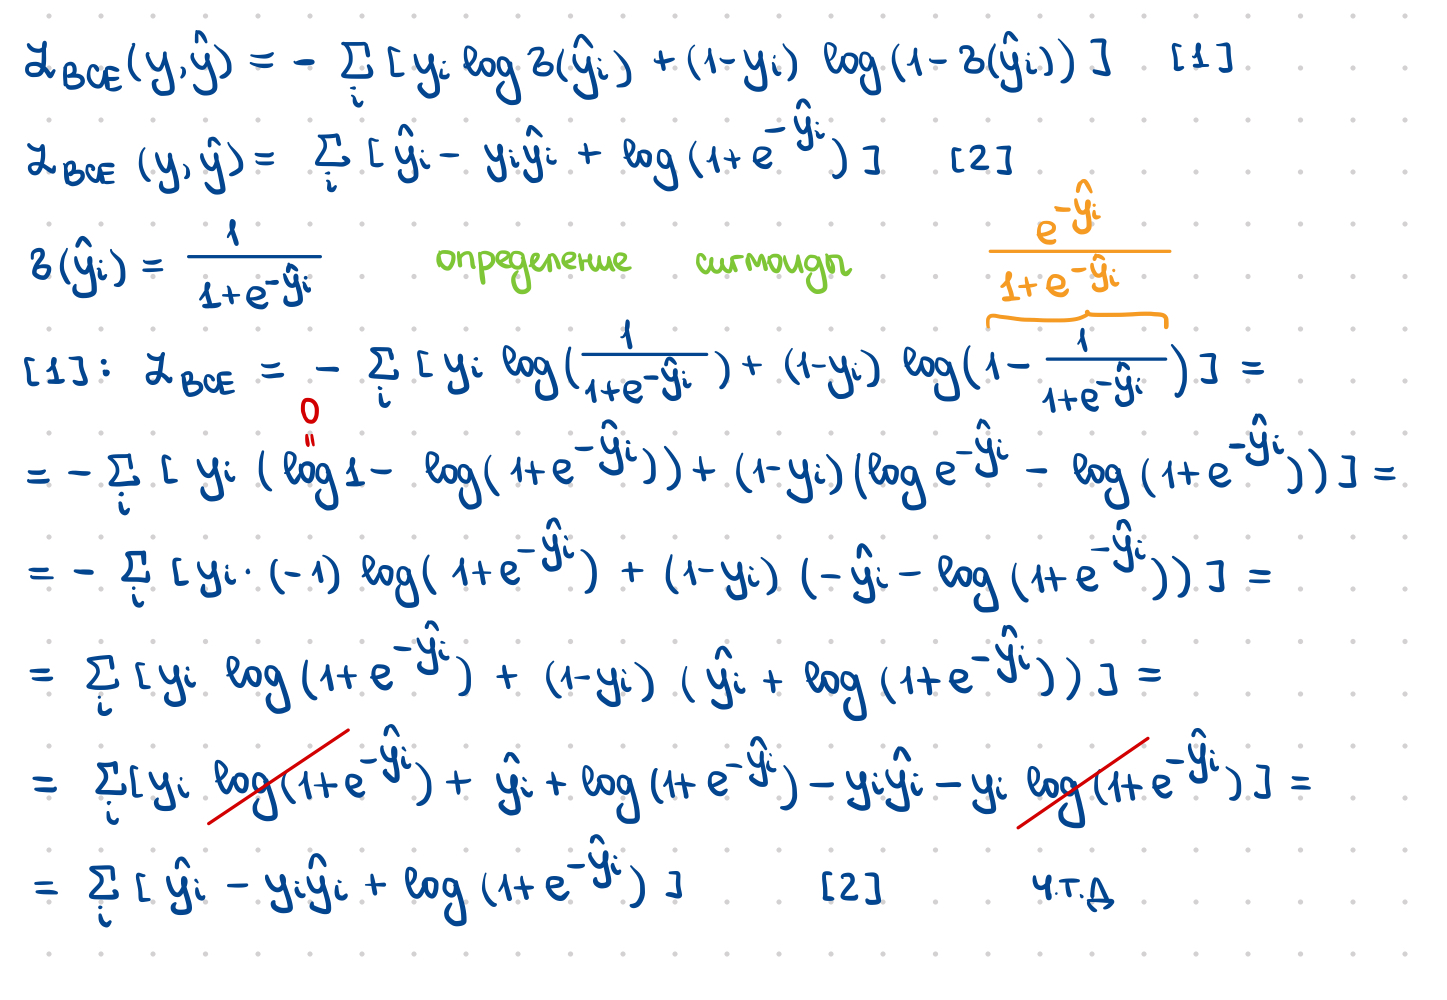

### Реализуйте в коде оба варианта лосса [1 балл]

Реализуйте следующие функции:

*   `bce_true()` - честная прямая реализация лосса с формулой $$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$
*   `bce_loss()` - реализация формулы, которую мы вывели $$\mathcal L_{BCE} = \hat y - y\hat y + \log\left(1+\exp(-\hat y)\right).$$

И сравните результаты функций с реализацией Pytorch:
*   `bce_torch()`
*   `bce_torch_with_logits()`

In [ ]:
def bce_true(y_pred, y_real):
  # TODO
  p = y_pred.sigmoid()
  return -torch.sum(y_real * torch.log(p) + (1 - y_real) * torch.log(1 - p))

def bce_loss(y_pred, y_real):
  # TODO
  return torch.sum(y_pred - y_real * y_pred + torch.log(1 + torch.exp(-y_pred)))

In [ ]:
bce_torch = nn.BCELoss(reduction='sum') # (sigmoid(y_pred), y_real)
bce_torch_with_logits = nn.BCEWithLogitsLoss(reduction='sum')

Проверим корректность работы на простом примере

In [ ]:
y_pred = torch.randn(3, 2, requires_grad=False)
y_true = torch.rand(3, 2, requires_grad=False)

print(f'BCE loss from scratch bce_loss             = {bce_loss(y_pred, y_true)}')
print(f'BCE loss честно посчитанный                = {bce_true(y_pred, y_true)}')
print(f'BCE loss from torch bce_torch              = {bce_torch(torch.sigmoid(y_pred), y_true)}')
print(f'BCE loss from torch with logits bce_torch  = {bce_torch_with_logits(y_pred, y_true)}')


BCE loss from scratch bce_loss             = 4.616026401519775
BCE loss честно посчитанный                = 4.616025924682617
BCE loss from torch bce_torch              = 4.616025924682617
BCE loss from torch with logits bce_torch  = 4.616025924682617


Инструкции `assert` в Python — это булевы выражения, которые проверяют, является ли условие истинным (`True`). Внизу в коде мы проверяем функция `bce_loss()` выдает тот же результат, что и функция из Pytorch или нет. Если равенства не будет, что будет означать, что результаты функций не совпадают, а значит вы неправильно реализовали фукнцию `bce_loss()`, `assert` возвратит ошибку.

Функция `numpy.isclose()` используется для сравнения двух чисел с учётом допустимой погрешности. Она особенно полезна при работе с числами с плавающей точкой, где точное сравнение может быть проблематичным из-за ограничений представления таких чисел в компьютере.

Как она работает?

`numpy.isclose(a, b, rtol=1e-05, atol=1e-08) `принимает два числа (`a` и `b`) и сравнивает их, учитывая относительную и абсолютную погрешность. Если разница между двумя числами меньше заданного порога, функция возвращает `True`, иначе — `False`.

Параметры:

    rtol: Относительная погрешность (по умолчанию 1e-05). Используется для определения разницы относительно большего значения.
    atol: Абсолютная погрешность (по умолчанию 1e-08). Определяет минимальную разницу, которую следует учитывать.

Мы будем использовать `assert` и `numpy.isclose()` для проверки корректности нашего кода.

In [ ]:
assert np.isclose(bce_loss(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true))
assert np.isclose(bce_loss(y_pred, y_true), bce_torch_with_logits(y_pred, y_true))
assert np.isclose(bce_true(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true))
assert np.isclose(bce_true(y_pred, y_true), bce_torch_with_logits(y_pred, y_true))

Давайте теперь посчитаем на простом примере, но с теми же размерностями, что и в датасете

In [ ]:
y_pred = torch.randn((2, 1, 3, 3), requires_grad=False)
y_true = torch.randint(0, 2, (2, 1, 3, 3))

print(f'BCE loss from scratch bce_loss            = {bce_loss(y_pred, y_true)}')
print(f'BCE loss честно посчитанный               = {bce_true(y_pred, y_true)}')
print(f'BCE loss from torch bce_torch             = {bce_torch(torch.sigmoid(y_pred), y_true.to(torch.float))}')
print(f'BCE loss from torch with logits bce_torch = {bce_torch_with_logits(y_pred, y_true.to(torch.float))}')

BCE loss from scratch bce_loss            = 14.737800598144531
BCE loss честно посчитанный               = 14.737801551818848
BCE loss from torch bce_torch             = 14.737801551818848
BCE loss from torch with logits bce_torch = 14.737800598144531


In [ ]:
assert np.isclose(bce_loss(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true.to(torch.float)))
assert np.isclose(bce_loss(y_pred, y_true), bce_torch_with_logits(y_pred, y_true.to(torch.float)))
assert np.isclose(bce_true(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true.to(torch.float)))
assert np.isclose(bce_true(y_pred, y_true), bce_torch_with_logits(y_pred, y_true.to(torch.float)))

Давайте посчитаем на реальных логитах и сегментационной маске:

In [ ]:
!gdown --folder 1EX0RW1TRQVkLmR1h6miCQqyhYPFyg28M

Retrieving folder contents
Processing file 1--WxvBdpMn_NOmYPf3a4au8MHzfx5baC labels.pt
Processing file 1-0A7_CS_vKiSCkgIDJ4joThCEcFedA3I logits.pt
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1--WxvBdpMn_NOmYPf3a4au8MHzfx5baC
To: /content/for_asserts/labels.pt
100% 1.18k/1.18k [00:00<00:00, 4.65MB/s]
Downloading...
From: https://drive.google.com/uc?id=1-0A7_CS_vKiSCkgIDJ4joThCEcFedA3I
To: /content/for_asserts/logits.pt
100% 1.18k/1.18k [00:00<00:00, 6.11MB/s]
Download completed


In [ ]:
path_to_dummy_samples = '/content/for_asserts'
dummpy_sample = {'logits': torch.load(f'{path_to_dummy_samples}/logits.pt'),
                 'labels': torch.load(f'{path_to_dummy_samples}/labels.pt')}
dummpy_sample['labels'] = dummpy_sample['labels'].to(device)
dummpy_sample['logits'] = dummpy_sample['logits'].to(device)

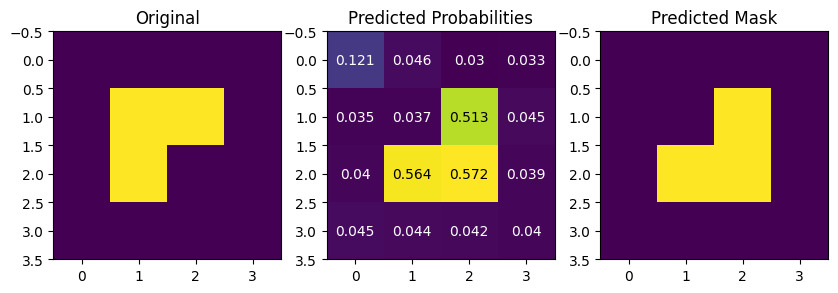

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize= (10, 3*10))

ax1.imshow(dummpy_sample['labels'].squeeze(1)[0].cpu())
ax1.set_title("Original")

ax2.imshow(dummpy_sample['logits'].sigmoid().squeeze(1)[0].cpu())
for (j,i),label in np.ndenumerate(dummpy_sample['logits'].sigmoid().squeeze(1)[0].cpu()):
    if label < 0.5:
        color = 'white'
    else:
        color = 'black'
    ax2.text(i,j,round(label,3), color=color, ha='center',va='center')

ax2.set_title("Predicted Probabilities")

ax3.imshow((dummpy_sample['logits'].sigmoid() > 0.5).squeeze(1)[0].cpu())
ax3.set_title("Predicted Mask")
plt.show()

Проверяем на данном примере:

In [ ]:
bce_loss_score = bce_loss(dummpy_sample['logits'].cpu(), dummpy_sample['labels'].cpu())
bce_true_score = bce_true(dummpy_sample['logits'].cpu(), dummpy_sample['labels'].cpu())
bce_torch_score = bce_torch(torch.sigmoid(dummpy_sample['logits'].cpu()), dummpy_sample['labels'].cpu().float())
bce_torch_with_logits_score = bce_torch_with_logits(dummpy_sample['logits'].cpu(), dummpy_sample['labels'].cpu().float())
assert np.isclose(bce_loss_score, bce_torch_score)
assert np.isclose(bce_loss_score, bce_torch_with_logits_score)
assert np.isclose(bce_true_score, bce_torch_score)
assert np.isclose(bce_true_score, bce_torch_with_logits_score)

## Шаг 4. Модель SegNet [2 балла]

Ваше задание здесь состоит в том, чтобы реализовать SegNet архитектуру.

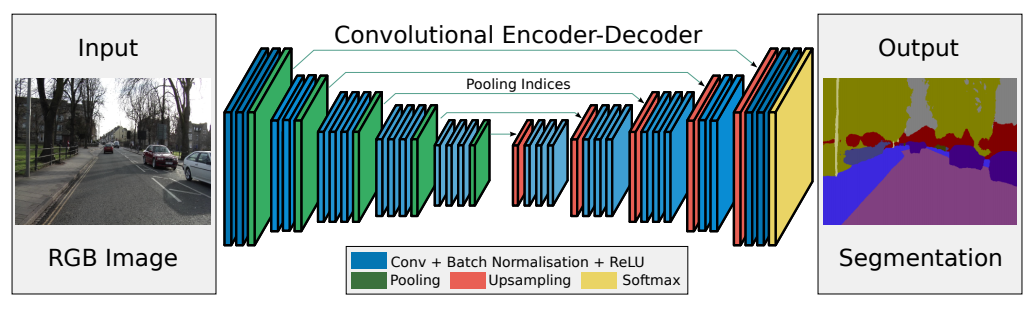

* Badrinarayanan, V., Kendall, A., & Cipolla, R. (2015). [SegNet: A deep convolutional
encoder-decoder architecture for image segmentation](https://arxiv.org/pdf/1511.00561.pdf)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
import torch.optim as optim
from time import time

from matplotlib import rcParams
rcParams['figure.figsize'] = (15,4)

Внимательно посмотрите из чего состоит модель и для чего выбраны те или иные блоки. Для этого скачаем и изучим feature extractor VGG-16, который лежит в основе SegNet.

In [ ]:
model_vgg16 = models.vgg16(weights = models.VGG16_Weights.IMAGENET1K_V1)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:09<00:00, 61.1MB/s]


In [ ]:
model_vgg16

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

Feature extractor VGG-16 состоит из 5 блоков:
- два блока со структурой:
Conv2d -> ReLU -> Conv2d -> ReLU -> MaxPool2d
- три блока со структурой:
Conv2d -> ReLU -> Conv2d -> ReLU -> Conv2d -> ReLU -> MaxPool2d

В первом блоке - на входе три канала (по числу каналов в изображениях), которые конволюционный слой преобразует в 64 канала.

Во втором, третьем и четвертом блоках первый конволюционный слой удваивает количество каналов, а последующие конволюционные слои не меняют количество каналов.

В последнем блоке число каналов от слоя к слою не меняется.

Теперь напишем код одного блока энкодера нашей модели SegNet.  

In [ ]:
# Параметрами блока будут:
# - количество каналов на входе
# - количество каналов на выходе
# - глубина блока (2 или 3, по количеству конволюционных слоев)
# - kernel_size и padding

class EncoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, depth, kernel_size = 3, padding = 1):
        super(EncoderBlock, self).__init__() # инициируем экземляр класса, наследующего от nn.Module
        self.layers = nn.ModuleList() # в self.layers будем добавлять слои блока
        # дальше реализуем то, что на картинке выше обозначено Conv + Batch Normalization + ReLU
        self.layers.append(nn.Conv2d(in_channels = in_channels, out_channels = out_channels, kernel_size = kernel_size, padding = padding))
        self.layers.append(nn.BatchNorm2d(out_channels))
        self.layers.append(nn.ReLU(inplace=True))

        # цикл for помогает использовать один код для блоков как с глубиной 2, так и с глубиной 3
        for i in range(depth - 1):
            self.layers.append(nn.Conv2d(in_channels = out_channels, out_channels = out_channels, kernel_size = kernel_size, padding = padding))
            self.layers.append(nn.BatchNorm2d(out_channels))
            self.layers.append(nn.ReLU(inplace=True))

        self.maxpooling = nn.MaxPool2d(kernel_size=2, stride=2, return_indices=True) #добавляем MaxPool с индексами для последующего Unpooling

    # Обратите внимание: на вход метод forward() получает карту признаков (х),
    # а возвращает карту признаков и индексы для последующего Unpooling

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        x, indices = self.maxpooling(x)
        return x, indices

По аналогии напишите код одного блока декодера.

К карте признаков на входе каждого блока применяется nn.MaxUnpool2d с индексами из симметричного блока энкодера. Затем повторяется связка Conv + Batch Normalization + ReLU. Количество каналов меняется зеркально блокам энкодера:
- в первом блоке декодера количество каналов не меняется
- во 2-4 блоках декодера количество каналов уменьшается в 2 раза после прохождения последнего конволюционного слоя
- на выходе из последнего блока декодера 1 канал

Обратите внимание, что после последней конволюции последнего блока декодера не применяется батч-нормализация и функция активации.

In [ ]:
class DecoderBlock(nn.Module):
  # TODO
  def __init__(self, in_channels, out_channels, depth, kernel_size = 3, padding = 1, last: bool = False):
    super(DecoderBlock, self).__init__()

    self.layers = nn.ModuleList()
    self.unpooling = nn.MaxUnpool2d(kernel_size=2, stride=2)
    # цикл for помогает использовать один код для блоков как с глубиной 2, так и с глубиной 3
    for i in range(depth - 1):
        self.layers.append(nn.ConvTranspose2d(in_channels=in_channels, out_channels=in_channels, kernel_size=kernel_size, padding=padding))
        self.layers.append(nn.BatchNorm2d(num_features=in_channels))
        self.layers.append(nn.ReLU(inplace=True))

    # последний конволюционный слой
    self.layers.append(nn.ConvTranspose2d(in_channels=in_channels, out_channels=out_channels, kernel_size=kernel_size, padding=padding))
    if not last:
        self.layers.append(nn.BatchNorm2d(num_features=out_channels))
        self.layers.append(nn.ReLU(inplace=True))

  def forward(self, x, indices):
    x = self.unpooling(x, indices)
    for layer in self.layers:
        x = layer(x)
    return x

Соединим блоки энкодера и декодера в модель SegNet:

In [ ]:
class SegNet(nn.Module):
    def __init__(self, in_channels = 3, out_channels = 1, num_features = 64) -> None:
        super(SegNet, self).__init__()

        # Encoder
        self.encoder0 = EncoderBlock(in_channels, num_features, depth=2)
        self.encoder1 = EncoderBlock(num_features, num_features * 2, depth=2)
        # TODO
        self.encoder2 = EncoderBlock(num_features * 2, num_features * 4, depth=3)
        self.encoder3 = EncoderBlock(num_features * 4, num_features * 8, depth=3)

        # Encoder bottleneck - количество каналов на входе и на выходе одинаково
        # TODO
        self.encoder4 = EncoderBlock(num_features * 8, num_features * 8, depth=3)

        # Decoder bottleneck
        # TODO
        self.decoder4 = DecoderBlock(num_features * 8, num_features * 8, depth=3)

        # Decoder
        # TODO
        self.decoder3 = DecoderBlock(num_features * 8, num_features * 4, depth=3)
        self.decoder2 = DecoderBlock(num_features * 4, num_features * 2, depth=3)
        self.decoder1 = DecoderBlock(num_features * 2, num_features, depth=2)
        # последний блок декодера
        self.decoder0 = DecoderBlock(num_features, out_channels, depth=2, last=True)

    def forward(self, x):
        # encoder
        x, indices0 = self.encoder0(x)
        # TODO
        x, indices1 = self.encoder1(x)
        x, indices2 = self.encoder2(x)
        x, indices3 = self.encoder3(x)
        x, indices4 = self.encoder4(x)

        # decoder
        # TODO
        x = self.decoder4(x, indices4)
        x = self.decoder3(x, indices3)
        x = self.decoder2(x, indices2)
        x = self.decoder1(x, indices1)
        output = self.decoder0(x, indices0)

        return output  # no activation

## Шаг 5. Тренировка модели [1 балл]

Напишите функции для обучения модели.

In [ ]:
from tqdm.notebook import tqdm

In [ ]:
# TODO
def fit_one_epoch(model, train_dataloader, optimizer, loss_fn, device):
    iou_mean = 0
    loss_mean = 0

    model.train()
    for X_batch, y_batch in tqdm(train_dataloader):
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()

        outp = model(X_batch)
        loss = loss_fn(outp, y_batch)

        pred_mask = (outp.sigmoid() > 0.5).to(int)
        iou_val = iou_score(pred_mask, y_batch)

        loss.backward()
        optimizer.step()

        loss_mean += loss.item() / len(train_dataloader)
        iou_mean += iou_val.item() / len(train_dataloader)

    return iou_mean, loss_mean

In [ ]:
# TODO
def eval_one_epoch(model, val_dataloader, loss_fn, device):
    iou_mean = 0
    loss_mean = 0

    model.eval()
    for X_batch, y_batch in tqdm(val_dataloader):
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        with torch.no_grad():
            outp = model(X_batch)
            loss = loss_fn(outp, y_batch)

            pred_mask = (outp.sigmoid() > 0.5).to(int)
            iou_val = iou_score(pred_mask, y_batch)

            loss_mean += loss.item() / len(val_dataloader)
            iou_mean += iou_val.item() / len(val_dataloader)

    return model, iou_mean, loss_mean

In [ ]:
# TODO
def train(model, max_epochs, train_dataloader, val_dataloader, optimizer, loss_fn, folder_name, device, checkpoint_path, scheduler=None):
    statistics = {
        f'train_IoU': [],
        f'val_IoU': [],
        'train_loss': [],
        'val_loss': []
    }
    best_val_loss = float('inf')
    best_model = None

    for epoch in tqdm(range(max_epochs)):
        print(f'\nEpoch: {epoch + 1}')
        metric_train, loss_train = fit_one_epoch(model, train_dataloader, optimizer, loss_fn, device)
        print(f'\nTrain IoU: {metric_train}')

        model, metric_val, loss_val = eval_one_epoch(model, val_dataloader, loss_fn, device)
        print(f'\nVal IoU: {metric_val}')

        if loss_val < best_val_loss:
            best_val_loss = loss_val
            best_model = model
            torch.save(model.state_dict(), f'{checkpoint_path}/{folder_name}/epoch_{epoch}_best_val_loss.pt')

        statistics[f'train_IoU'].append(metric_train)
        statistics[f'val_IoU'].append(metric_val)
        statistics['train_loss'].append(loss_train)
        statistics['val_loss'].append(loss_val)

        if scheduler is not None:
            scheduler.step()

    return best_model, statistics

Обучите модель **SegNet**. В качестве оптимайзера можно взять Adam.

In [ ]:
# TODO
model_segnet = SegNet()
model_segnet.to(device)

optimizer = torch.optim.Adam(model_segnet.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

checkpoint_path = '/content/checkpoints'

In [ ]:
# !rm -r /content/checkpoints

In [ ]:
!mkdir /content/checkpoints

In [ ]:
!mkdir /content/checkpoints/IoU_score

In [ ]:
num_epochs = 30
best_segnet, statistics_segnet = train(model_segnet, num_epochs, train_dataloader, valid_dataloader, \
                                       optimizer, criterion, 'IoU_score', device, checkpoint_path)

  0%|          | 0/30 [00:00<?, ?it/s]


Epoch: 1


  0%|          | 0/4 [00:00<?, ?it/s]


Train IoU: 0.12389395339414477


  0%|          | 0/2 [00:00<?, ?it/s]

...


Val IoU: 0.7616666257381439

Epoch: 30


  0%|          | 0/4 [00:00<?, ?it/s]


Train IoU: 0.7619508355855942


  0%|          | 0/2 [00:00<?, ?it/s]


Val IoU: 0.7642444372177124


In [ ]:
def plot_statistics(num_epochs, loss_name, statistics):
    plt.figure(figsize=(10, 12))

    plt.subplot(2, 1, 1)
    plt.title('IoU score dynamics')

    plt.plot(statistics[f'train_IoU'], label=f'IoU_train')
    plt.plot(statistics[f'val_IoU'], label=f'IoU_val')

    plt.xlabel('epoch')
    plt.xticks(range(0, num_epochs, 2))

    plt.legend()
    plt.grid(linestyle='--')


    plt.subplot(2, 1, 2)
    plt.title(f'{loss_name} loss dynamics')

    plt.plot(statistics['train_loss'], label='loss_train')
    plt.plot(statistics['val_loss'], label='loss_val')

    plt.xlabel('epoch')
    plt.xticks(range(0, num_epochs, 2))

    plt.legend()
    plt.grid(linestyle='--')

    plt.show()

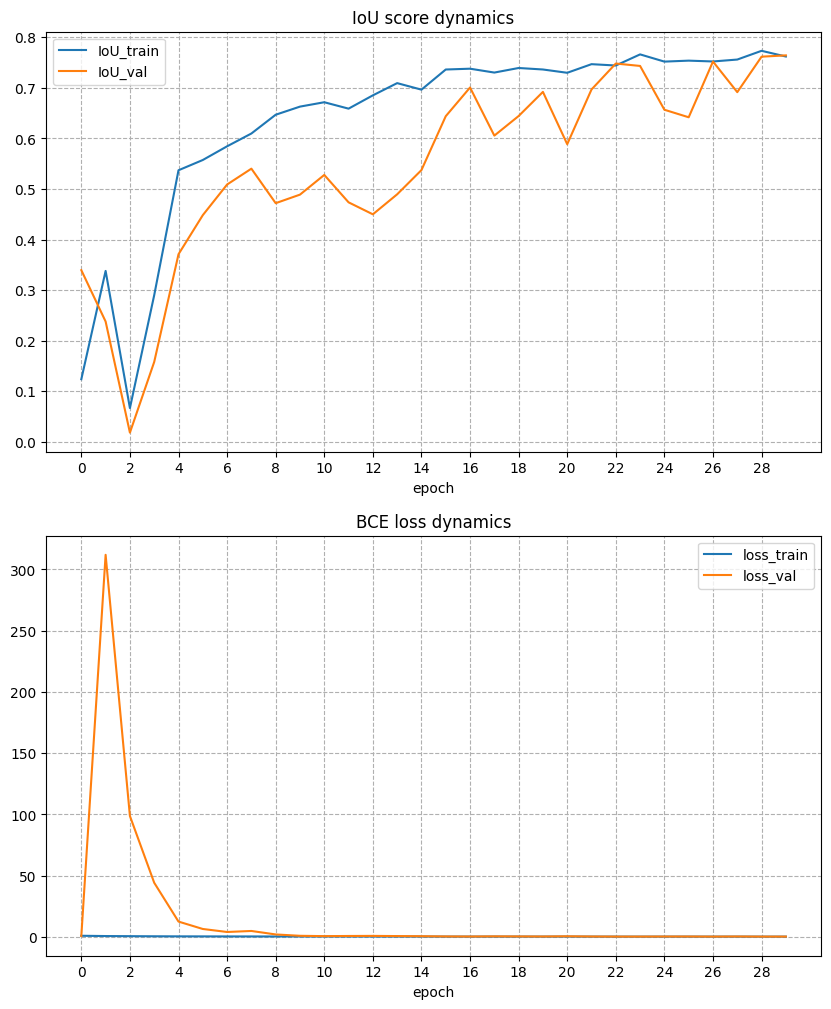

In [ ]:
plot_statistics(num_epochs, 'BCE', statistics_segnet)

## Шаг 6. Инференс [1 балл]

После обучения модели напишите функцию теста, воспользуйтесь лучшим чекпоинтом и протестируйте работу модели на тестовой выборке.

In [ ]:
# TODO
def test(model, test_dataloader, device, checkpoint_path, checkpoint_name, plot=True):
    iou_mean = 0

    model.load_state_dict(torch.load(f'{checkpoint_path}/{checkpoint_name}'))
    model.to(device)

    model.eval()

    for X_batch, y_batch in test_dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        with torch.no_grad():
            outp = model(X_batch)
            pred_mask = (outp.sigmoid() > 0.5).to(int)
            iou_val = iou_score(pred_mask, y_batch)
            iou_mean += iou_val.item()

        # отрисовываем произвольные 3 объекта из первого батча
        if plot:
            idx = np.random.choice(batch_size, size=3, replace=False)
            fig, axes = plt.subplots(3, 3, figsize=(3*3, 3*3))

            for i, val_idx in enumerate(idx):
                orig_img = X_batch[val_idx].permute(1, 2, 0).cpu().detach().numpy()
                orig_mask = y_batch[val_idx][0].cpu().detach().numpy()

                preds = outp[val_idx]
                probabilities = preds.sigmoid()
                mask = (probabilities > 0.5).to(int)
                metric = iou_score(mask, y_batch[val_idx])

                mask = mask[0].cpu().detach().numpy()

                axes[i, 0].imshow(orig_img)
                axes[i, 0].set_title('Original image')

                axes[i, 1].imshow(orig_mask, cmap='gray')
                axes[i, 1].set_title('Original mask')

                axes[i, 2].imshow(mask, cmap='gray')
                axes[i, 2].set_title(f'Predicted mask with IoU = {metric:.2f}')

            plt.tight_layout()
            plt.show()

            plot = False

    iou_mean = iou_mean / len(test_dataloader)

    return iou_mean

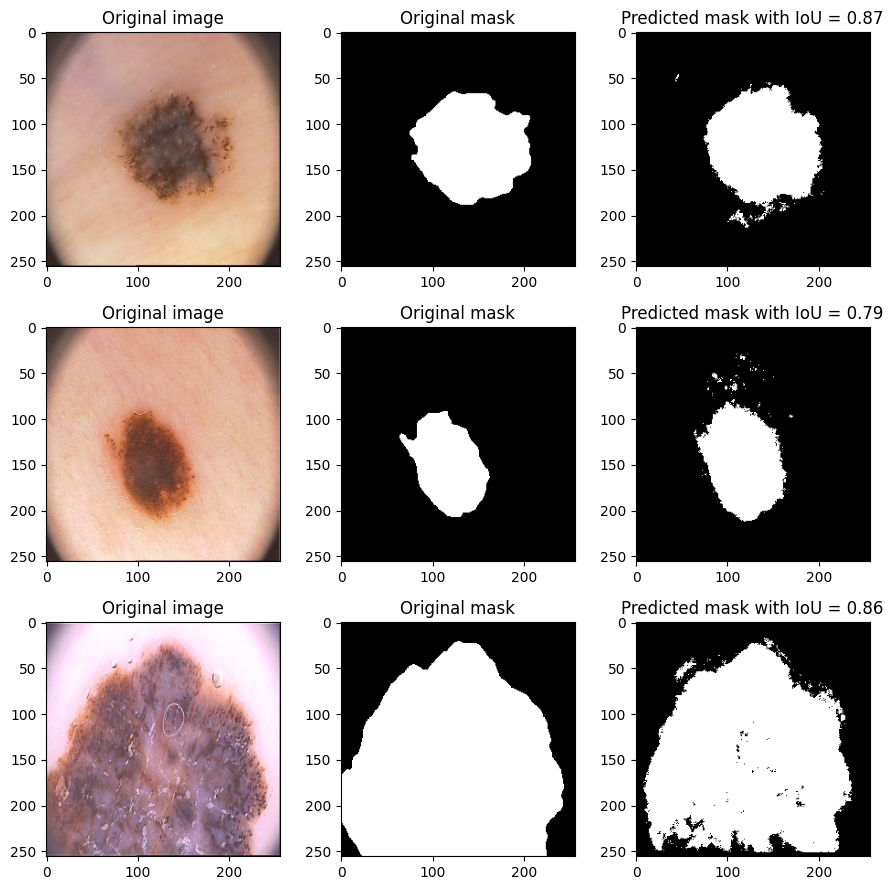

In [ ]:
best_checkpoint_path = '/content/checkpoints/IoU_score'
best_checkpoint_name = 'epoch_26_best_val_loss.pt'
metric_test_segnet = test(model_segnet, test_dataloader, device, best_checkpoint_path, best_checkpoint_name)

In [ ]:
print(f'SegNet IoU score on test: {metric_test_segnet:.2f}')

SegNet IoU score on test: 0.74


# Задания: Мир других лоссов!

## Пробуем другие функции потерь [2 балла]

В данном разделе вам потребуется имплементировать две функции потерь: DICE и Focal loss.


### Dice Loss

**1. Dice coefficient:** Учитывая две маски $X$ и $Y$, общая метрика для измерения расстояния между этими двумя масками задается следующим образом:

$$D(X,Y)=\frac{2|X\cap Y|}{|X|+|Y|}$$

В терминах матрицы ошибок она будет считаться следующим образом:

$$D(X,Y) = \frac{2TP}{2TP + FP + FN}$$

Эта функция не является дифференцируемой, но это необходимое свойство для градиентного спуска. В данном случае мы можем приблизить его с помощью:

$$\mathcal L_D(X,Y) = 1- D(X, Y)$$

**Hints** (!):

1. Не забудьте подумать о численной нестабильности, возникающей в математической формуле при ситуации, когда $\frac{0}{0}$, т.е. вам нужно добавить очень маленькое число, например $\epsilon = 1e^{-8}$, в обе части дроби при подсчете $D(X,Y)$:

$$D(X,Y) = \frac{2TP + ϵ}{2TP + FP + FN + ϵ}$$

2. Dice метрика(!), не лосс, считается похожим образом как IoU:

    2.1. На вход вам приходят logits, т.е. значения от $-∞$ до $∞$. Их переводим в вероятности от 0 до 1 при помощи функции Sigmoid.

    2.2. Фиксируем порог, например threshold=0.5, и всему что ниже порога ставим значение 0, всему что выше 1. Получаем предсказанную маску из 0 и 1.

    2.3. Считаем TP, FP, FN

    2.4. Считаем DICE метрику по формуле

Вы можете прописать для себя функцию `dice_score()` и сравнить с результатами работы функции из библиотеки `torchmetrics`.

3. Но с метрикой есть проблема, что она не дифференцируема, и если вы захотите просто взять и прописать `dice_loss` = 1 - `dice_score`, Pytorch поругается на вас и скажет, что это недифференцируемая метрика. Чтобы посчитать dice_loss делаем следующие шаги:

    3.1. На вход вам приходят logits, т.е. значения от $-∞$ до $∞$. Их переводим в вероятности от 0 до 1 при помощи функции Sigmoid.

    3.2. Здесь нам уже не нужно фиксировать порог, мы просто работаем с вероятностями. Значения вероятностей дифференцируемы и через них будут протекать градиенты.

    3.3. Считаем TP, FP, FN также как и в Dice метрике, только вместо маски, подаем вероятности.

    3.4. Считаем DICE метрику по формуле

    3.5. Считаем лосс как Loss = 1 - DICE

Итак, давайте сначала пропишем dice_score.

In [ ]:
from torchmetrics import ConfusionMatrix

In [ ]:
def dice_score(logits: torch.Tensor, labels: torch.Tensor, threshold: float = 0.5):
    '''
    Это именно метрика, не лосс.
    '''
    # TODO
    probabilities = logits.sigmoid()
    preds = (probabilities > threshold).type(torch.int)

    cm = ConfusionMatrix(task='binary', num_classes=2).to(device)
    conf_matrix = cm(preds, labels)

    TN, FP = conf_matrix[0]
    FN, TP = conf_matrix[1]

    score = 2 * TP / (2 * TP + FP + FN)

    return score

Проверим на корректность функцию dice_score:

In [ ]:
from torchmetrics.segmentation import DiceScore

dice = DiceScore(num_classes=1, average='micro').to(device)
dice((dummpy_sample['logits'].sigmoid() >= 0.5).to(int), dummpy_sample['labels'].to(int))

tensor(0.6667)

In [ ]:
dice_score(dummpy_sample['logits'], dummpy_sample['labels'])

tensor(0.6667)

In [ ]:
"""
если вы используете версию библиотеки 0.11.4, то можно взять torchmetrics.classification.Dice():
from torchmetrics.classification import Dice
dice = Dice(average='micro').to(device)
"""

In [ ]:
assert dice((dummpy_sample['logits'].sigmoid() >= 0.5).to(int), \
            dummpy_sample['labels'].to(int)) == dice_score(dummpy_sample['logits'], dummpy_sample['labels'])

Давайте теперь пропишем лосс и воспользуемся библиотекой `segmentation-models-pytorch`, чтобы убедиться в корректности нашей функции.

In [ ]:
def dice_loss(logits: torch.Tensor, labels: torch.Tensor, eps=1e-07):
    '''
    Это лосс.
    '''
    # TODO
    probabilities = logits.sigmoid()

    probabilities = probabilities.view(-1)
    labels = labels.view(-1)

    TP = (probabilities * labels).sum()
    FP = (probabilities * (1 - labels)).sum()
    FN = ((1 - probabilities) * labels).sum()

    dice_score = (2 * TP + eps) / (2 * TP + FP + FN + eps)

    loss = 1 - dice_score

    return loss

Проверка на корректность:

In [ ]:
# проверьте, что у вас установлена библиотека
!pip install segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 3.8 MB/s eta 0:00:00


In [ ]:
from segmentation_models_pytorch.losses import DiceLoss

dice_loss_torch = DiceLoss(mode='binary')
dice_loss_torch(dummpy_sample['logits'], dummpy_sample['labels'].to(int))

tensor(0.5756)

In [ ]:
dice_loss(dummpy_sample['logits'], dummpy_sample['labels'])

tensor(0.5756)

In [ ]:
assert dice_loss_torch(dummpy_sample['logits'], dummpy_sample['labels'].to(int)) == dice_loss(dummpy_sample['logits'], dummpy_sample['labels'])

### Focal Loss

[**2. Focal loss:**](https://arxiv.org/pdf/1708.02002.pdf)

Окей, мы уже с вами умеем делать BCE loss:

$$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

Проблема с этой потерей заключается в том, что она имеет тенденцию приносить пользу классу **большинства** (фоновому) по отношению к классу **меньшинства** ( переднему). Поэтому обычно применяются весовые коэффициенты к каждому классу:

$$\mathcal L_{wBCE}(y, \hat y) = -\sum_i \alpha_i\left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

Традиционно вес $\alpha_i$ определяется как обратная частота класса этого пикселя $i$, так что наблюдения миноритарного класса весят больше по отношению к классу большинства.


Из оригинальной статьи по [Focal Loss](https://arxiv.org/pdf/1708.02002.pdf):

$$p_t = \sigma(\hat y_i)y_i + (1 - \sigma(\hat y_i)) (1-y_i)$$

$$\mathcal L_{focal}(y, \hat y) = (1 - p_t)^{\gamma} \mathcal L_{BCE}(y_i, \hat y_i).$$

$$\mathcal L_{focal}(y, \hat y) = -\sum_i (1 - p_t)^{\gamma} \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

$$\mathcal L_{focal}(y, \hat y) = -\sum_i (1 - (\sigma(\hat y_i)y_i + (1 - \sigma(\hat y_i)) (1-y_i)))^{\gamma} \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

In [ ]:
def focal_loss(y_real, y_pred, eps = 1e-8, gamma = 2):
    # TODO
    p = y_pred.sigmoid()
    p_t = p * y_real + (1 - p) * (1 - y_real)

    bce_part = y_real * torch.log(p) + (1 - y_real) * torch.log(1 - p)
    loss = -torch.sum((1 - p_t) ** gamma * bce_part)

    return loss

Проверка корректности функции:

In [ ]:
from torchvision.ops import sigmoid_focal_loss
sigmoid_focal_loss(dummpy_sample['logits'], dummpy_sample['labels'], alpha=-1, gamma=2, reduction='sum')

tensor(3.6161)

In [ ]:
focal_loss(dummpy_sample['labels'], dummpy_sample['logits'], gamma=2.0)

tensor(3.6161)

In [ ]:
assert np.allclose(sigmoid_focal_loss(dummpy_sample['logits'], dummpy_sample['labels'], alpha=-1, gamma=2, reduction='sum'),
                      focal_loss(dummpy_sample['labels'], dummpy_sample['logits'], gamma=2.0))

## [BONUS] Мир сегментационных лоссов [5 баллов]

В данном блоке предлагаем вам написать одну функцию потерь самостоятельно. Для этого необходимо прочитать статью и имплементировать ее, и провести численное сравнение с предыдущими функциями.

* [Physiological Inspired Deep Neural Networks for Emotion Recognition](https://ieeexplore.ieee.org/stamp/stamp.jsp?arnumber=8472816&tag=1)". IEEE Access, 6, 53930-53943.

* [Boundary loss for highly unbalanced segmentation](https://arxiv.org/abs/1812.07032)

* [Tversky loss function for image segmentation using 3D fully convolutional deep networks](https://arxiv.org/abs/1706.05721)

* [Correlation Maximized Structural Similarity Loss for Semantic Segmentation](https://arxiv.org/abs/1910.08711)

* [Topology-Preserving Deep Image Segmentation](https://papers.nips.cc/paper/8803-topology-preserving-deep-image-segmentation)

Реализуем Tversky loss:

In [ ]:
def tversky_loss(logits: torch.Tensor, labels: torch.Tensor, alpha=0.5, beta=0.5, eps=1e-7):
    probabilities = logits.sigmoid()

    probabilities = probabilities.view(-1)
    labels = labels.view(-1)

    TP = (probabilities * labels).sum()
    FP = (probabilities * (1 - labels)).sum()
    FN = ((1 - probabilities) * labels).sum()

    tversky_index = (TP + eps) / (TP + alpha * FP + beta * FN + eps)

    loss = 1 - tversky_index
    loss = loss.squeeze()

    return loss

In [ ]:
tversky_loss(dummpy_sample['logits'], dummpy_sample['labels'])

tensor(0.5756)

In [ ]:
from segmentation_models_pytorch.losses import TverskyLoss

In [ ]:
tversky_loss_torch = TverskyLoss(mode='binary', from_logits=True)

In [ ]:
tversky_loss_torch(dummpy_sample['logits'], dummpy_sample['labels'])

tensor(0.5756)

In [ ]:
assert np.allclose(tversky_loss(dummpy_sample['logits'], dummpy_sample['labels']),
                   tversky_loss_torch(dummpy_sample['logits'], dummpy_sample['labels']))

Tvesky loss похож на dice loss, отличие лишь в том, что в Tversky loss FP и FN учитываются с коэфициентами $\alpha$ и $\beta$ соответственно, а TP берется с коэффициентом 1.

## Обучите SegNet на новых лоссах

**Задание**: обучите SegNet на новых лоссах и сравните все три лосса:
*   При каком лоссе модель сходится быстрее?
*   При каком лоссе модель выдает наилучшую метрику?

Напишите развернутый ответ на вопросы.



In [ ]:
!mkdir /content/checkpoints/dice_loss

In [ ]:
del model_segnet
torch.cuda.empty_cache()

In [ ]:
# dice loss
model_segnet = SegNet()
model_segnet.to(device)

optimizer = torch.optim.Adam(model_segnet.parameters(), lr=1e-3)
criterion = DiceLoss(mode='binary')

In [ ]:
num_epochs = 30
best_segnet_dice, statistics_segnet_dice = train(model_segnet, num_epochs, train_dataloader, valid_dataloader, \
                                       optimizer, criterion, 'dice_loss', device, checkpoint_path)

  0%|          | 0/30 [00:00<?, ?it/s]


Epoch: 1


  0%|          | 0/4 [00:00<?, ?it/s]


Train IoU: 0.3070469833910465


  0%|          | 0/2 [00:00<?, ?it/s]

...


Val IoU: 0.7504415810108185

Epoch: 30


  0%|          | 0/4 [00:00<?, ?it/s]


Train IoU: 0.8144496828317642


  0%|          | 0/2 [00:00<?, ?it/s]


Val IoU: 0.7791052162647247


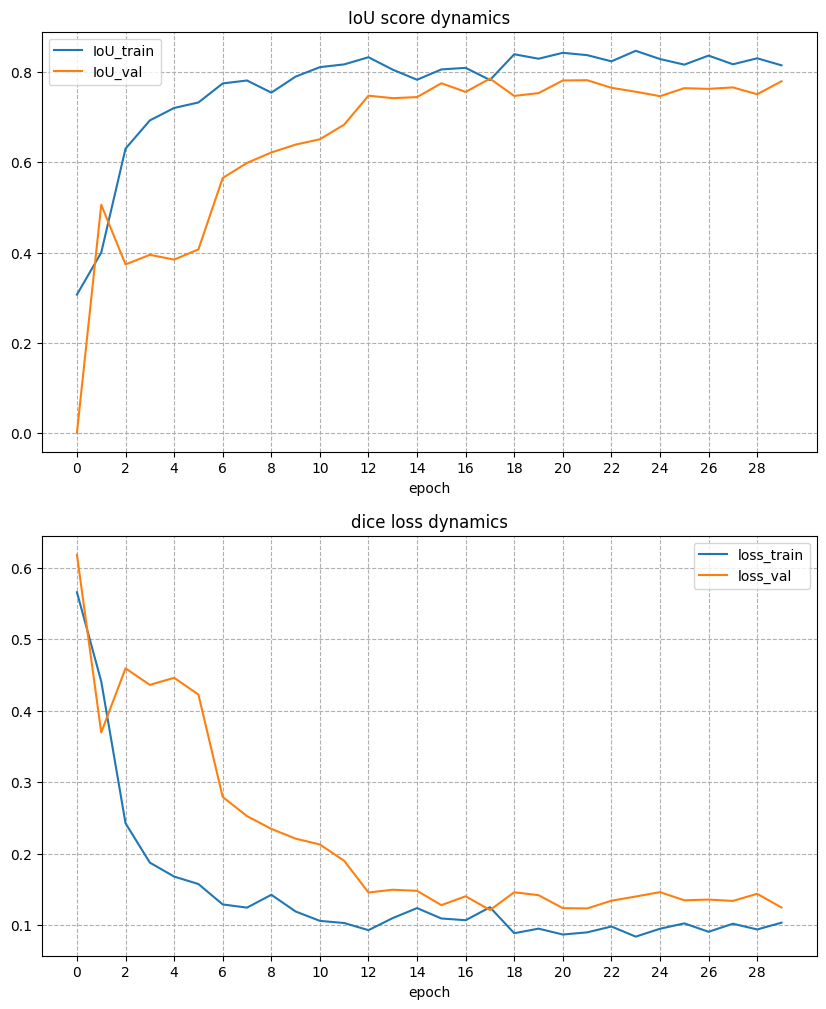

In [ ]:
plot_statistics(num_epochs, 'dice', statistics_segnet_dice)

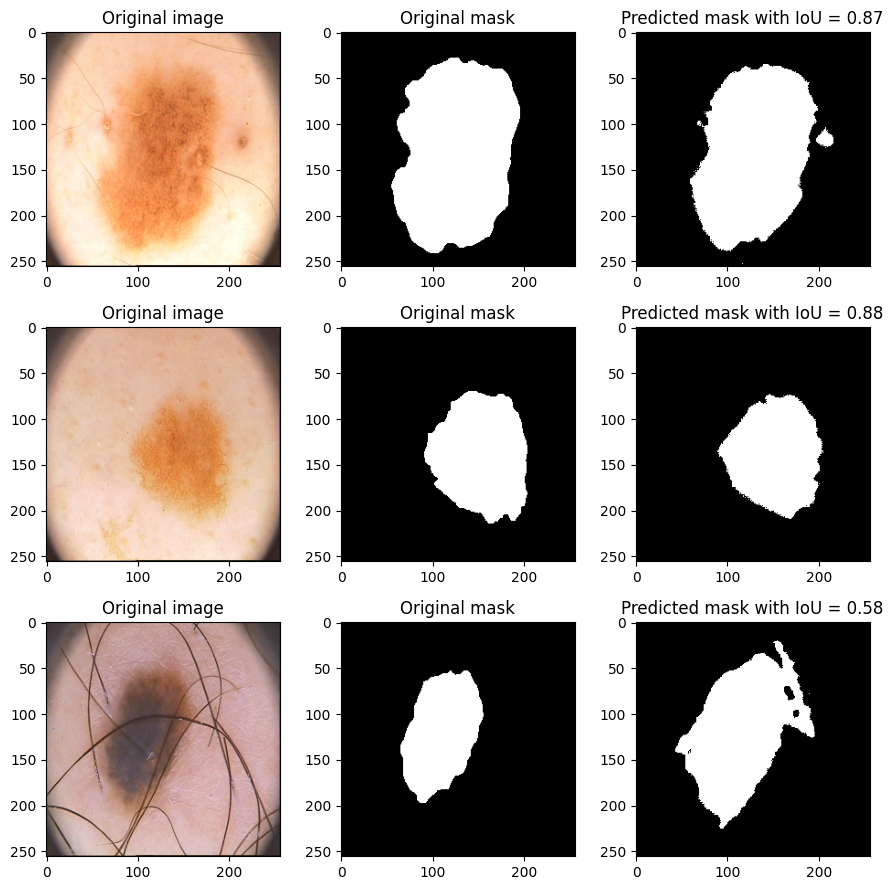

In [ ]:
best_checkpoint_path = '/content/checkpoints/dice_loss'
best_checkpoint_name = 'epoch_17_best_val_loss.pt'
metric_test_segnet = test(model_segnet, test_dataloader, device, best_checkpoint_path, best_checkpoint_name)

In [ ]:
print(f'SegNet with dice loss IoU score on test: {metric_test_segnet:.2f}')

SegNet with dice loss IoU score on test: 0.82


In [ ]:
!mkdir /content/checkpoints/focal_loss

In [ ]:
del model_segnet
torch.cuda.empty_cache()

In [ ]:
# focal loss
model_segnet = SegNet()
model_segnet.to(device)

optimizer = torch.optim.Adam(model_segnet.parameters(), lr=1e-3)
criterion = lambda logits, labels: sigmoid_focal_loss(
    logits, labels, reduction='mean'
)

checkpoint_path = '/content/checkpoints'

In [ ]:
num_epochs = 30
best_segnet_focal, statistics_segnet_focal = train(model_segnet, num_epochs, train_dataloader, valid_dataloader, \
                                       optimizer, criterion, 'focal_loss', device, checkpoint_path)

  0%|          | 0/30 [00:00<?, ?it/s]


Epoch: 1


  0%|          | 0/4 [00:00<?, ?it/s]


Train IoU: 0.1964789368212223


  0%|          | 0/2 [00:00<?, ?it/s]

...


Val IoU: 0.43893997371196747

Epoch: 30


  0%|          | 0/4 [00:00<?, ?it/s]


Train IoU: 0.5907122194766998


  0%|          | 0/2 [00:00<?, ?it/s]


Val IoU: 0.508028656244278


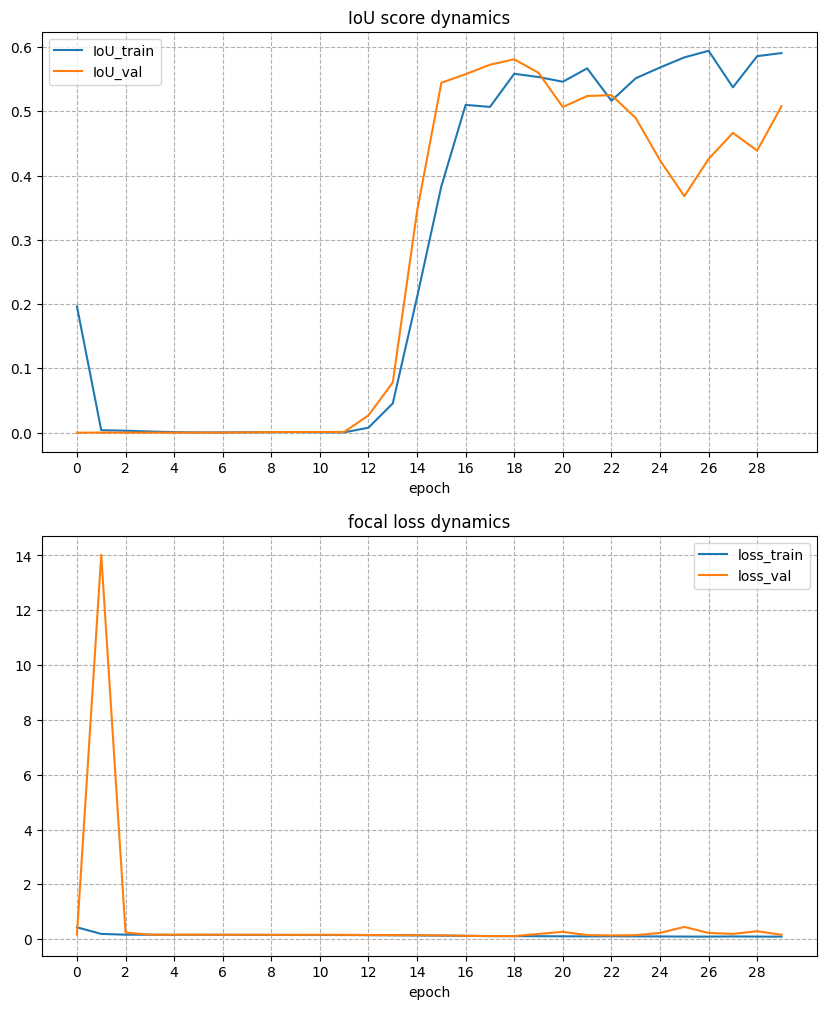

In [ ]:
plot_statistics(num_epochs, 'focal', statistics_segnet_focal)

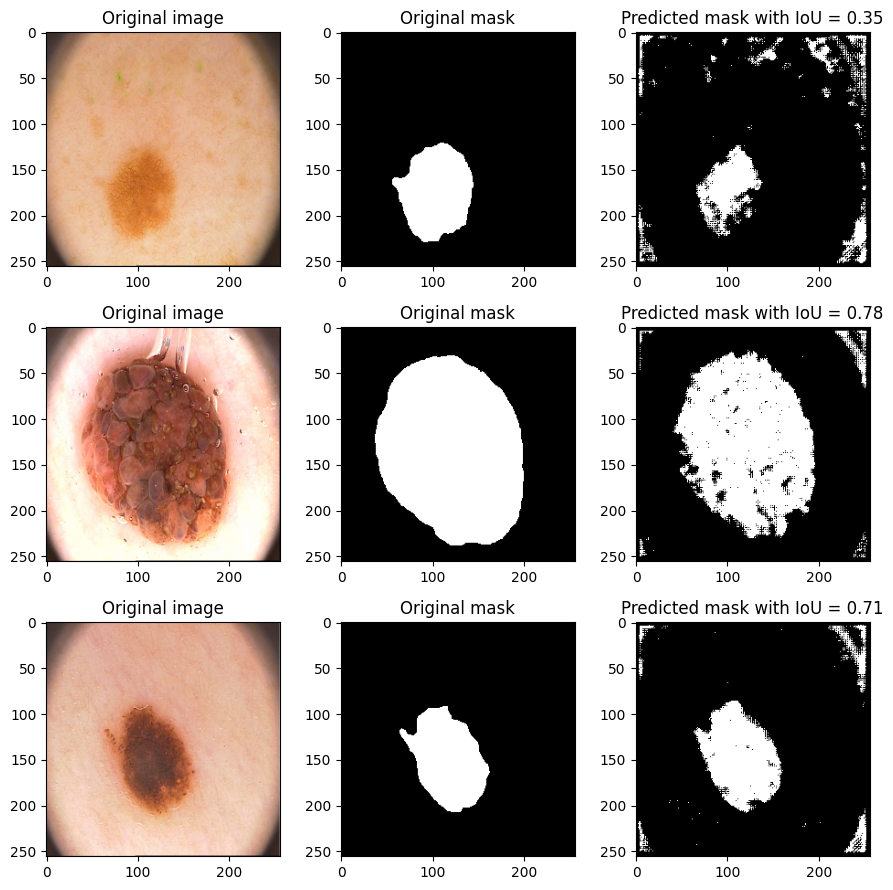

In [ ]:
best_checkpoint_path = '/content/checkpoints/focal_loss'
best_checkpoint_name = 'epoch_17_best_val_loss.pt'
metric_test_segnet = test(model_segnet, test_dataloader, device, best_checkpoint_path, best_checkpoint_name)

In [ ]:
print(f'SegNet with focal loss IoU score on test: {metric_test_segnet:.2f}')

SegNet with focal loss IoU score on test: 0.54


**Ответ:** Лучшее значение метрики на тесте достигается на dice loss.

# Задание: Новая модель!

## Модель U-Net [2 балла]

[**U-Net**](https://arxiv.org/abs/1505.04597) — это архитектура нейронной сети, которая получает изображение и выводит его. Первоначально он был задуман для семантической сегментации (как мы ее будем использовать), но он настолько успешен, что с тех пор используется в других контекстах. Получая на вход медицинское изображение, он выведет изображение в оттенках серого, где интенсивность каждого пикселя зависит от вероятности того, что этот пиксель принадлежит интересующей нас области.

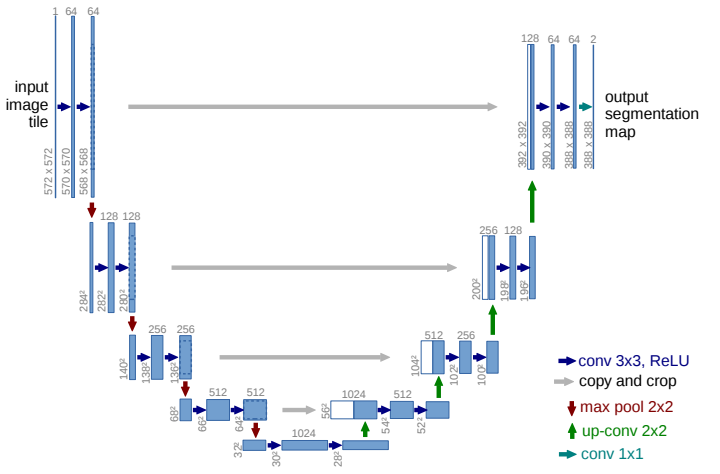

У нас в архитектуре все так же существует энкодер и декодер, как в **SegNet**, но отличительной особеностью данной модели являются *skip-conenctions*, соединяющие части декодера и энкодера. То есть для того чтобы передать на вход декодера тензор, мы конкатенируем симметричный выход с энкодера и выход предыдущего слоя декодера.

* Ronneberger, Olaf, Philipp Fischer, and Thomas Brox. "[U-Net: Convolutional networks for biomedical image segmentation.](https://arxiv.org/pdf/1505.04597.pdf)" International Conference on Medical image computing and computer-assisted intervention. Springer, Cham, 2015.

В оригинальной статье авторы не использовали padding внутри модели (это видно по тому, что размеры карты признаков уменьшаются на 2 каждый раз при движении от слоя к слою). При этом размеры входных изображений авторы единоразово увеличили при помощи mirror padding.

В этом домашнем задании вы можете применить альтернативный подход - сохранять размеры карт признаков при помощью padding = 1 во внутренних слоях.  

In [ ]:
import torch.nn.functional as F
import torch.nn as nn

Для реализации UNet вы можете написать классы блоков энкодера и декодера отдельно, как мы сделали при реализации SegNet.

In [ ]:
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, padding=1):
        super(BasicBlock, self).__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, padding=padding),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=kernel_size, padding=padding),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        output = self.layers(x)

        return output

In [ ]:
class EncoderUnet(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, padding=1):
        super(EncoderUnet, self).__init__()

        self.conv = BasicBlock(in_channels, out_channels, kernel_size, padding)
        self.maxpooling = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        x = self.conv(x)
        y = self.maxpooling(x)

        return x, y

In [ ]:
class DecoderUnet(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, padding=1):
        super(DecoderUnet, self).__init__()

        self.upsample = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
        self.conv = BasicBlock(in_channels, out_channels)

    def forward(self, x, y):
        x = self.upsample(x)
        skip_connection = torch.cat([x, y], dim=1)
        output = self.conv(skip_connection)

        return output

In [ ]:
class UNet(nn.Module):
    def __init__(self, n_class=1, n_features=64):
        super().__init__()

        # TODO
        self.encoder0 = EncoderUnet(in_channels=3, out_channels=n_features)
        self.encoder1 = EncoderUnet(in_channels=n_features, out_channels=n_features * 2)
        self.encoder2 = EncoderUnet(in_channels=n_features * 2, out_channels=n_features * 4)
        self.encoder3 = EncoderUnet(in_channels=n_features * 4, out_channels=n_features * 8)

        # bottleneck
        self.bottle_neck = BasicBlock(in_channels=n_features * 8, out_channels=n_features * 16)

        self.decoder3 = DecoderUnet(in_channels=n_features * 16, out_channels=n_features * 8)
        self.decoder2 = DecoderUnet(in_channels=n_features * 8, out_channels=n_features * 4)
        self.decoder1 = DecoderUnet(in_channels=n_features * 4, out_channels=n_features * 2)
        self.decoder0 = DecoderUnet(in_channels=n_features * 2, out_channels=n_features)

        # output layer
        self.out = nn.Conv2d(in_channels=n_features, out_channels=n_class, kernel_size=1)

    def forward(self, x):
        #  TODO
        skip_0, x = self.encoder0(x)
        skip_1, x = self.encoder1(x)
        skip_2, x = self.encoder2(x)
        skip_3, x = self.encoder3(x)

        x = self.bottle_neck(x)

        x = self.decoder3(x, skip_3)
        x = self.decoder2(x, skip_2)
        x = self.decoder1(x, skip_1)
        x = self.decoder0(x, skip_0)

        output = self.out(x)

        return output

## Обучите UNet

Задание: обучите UNet на всех трех лоссах: BCE, Dice, Focal и сравните результаты с SegNet:
*   Какая модель дает лучшие значения по метрике?
*   Какая модель дает лучшие значения по лоссам?
*   Какая модель обучается быстрее?
*   Сравните визуально результаты SegNet и UNet.

Напишите развернутый ответ на вопросы.



In [ ]:
!mkdir /content/checkpoints_unet

In [ ]:
!mkdir /content/checkpoints_unet/IoU_score

In [ ]:
# BCE loss
model_unet = UNet().to(device)

optimizer = torch.optim.Adam(model_unet.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

checkpoint_path = '/content/checkpoints_unet'

In [ ]:
num_epochs = 30
best_unet, statistics_unet = train(model_unet, num_epochs, train_dataloader, valid_dataloader, \
                                       optimizer, criterion, 'IoU_score', device, checkpoint_path)

  0%|          | 0/30 [00:00<?, ?it/s]


Epoch: 1


  0%|          | 0/4 [00:00<?, ?it/s]


Train IoU: 0.4738950952887535


  0%|          | 0/2 [00:00<?, ?it/s]

...


Val IoU: 0.7778042852878571

Epoch: 30


  0%|          | 0/4 [00:00<?, ?it/s]


Train IoU: 0.826516792178154


  0%|          | 0/2 [00:00<?, ?it/s]


Val IoU: 0.8005797863006592


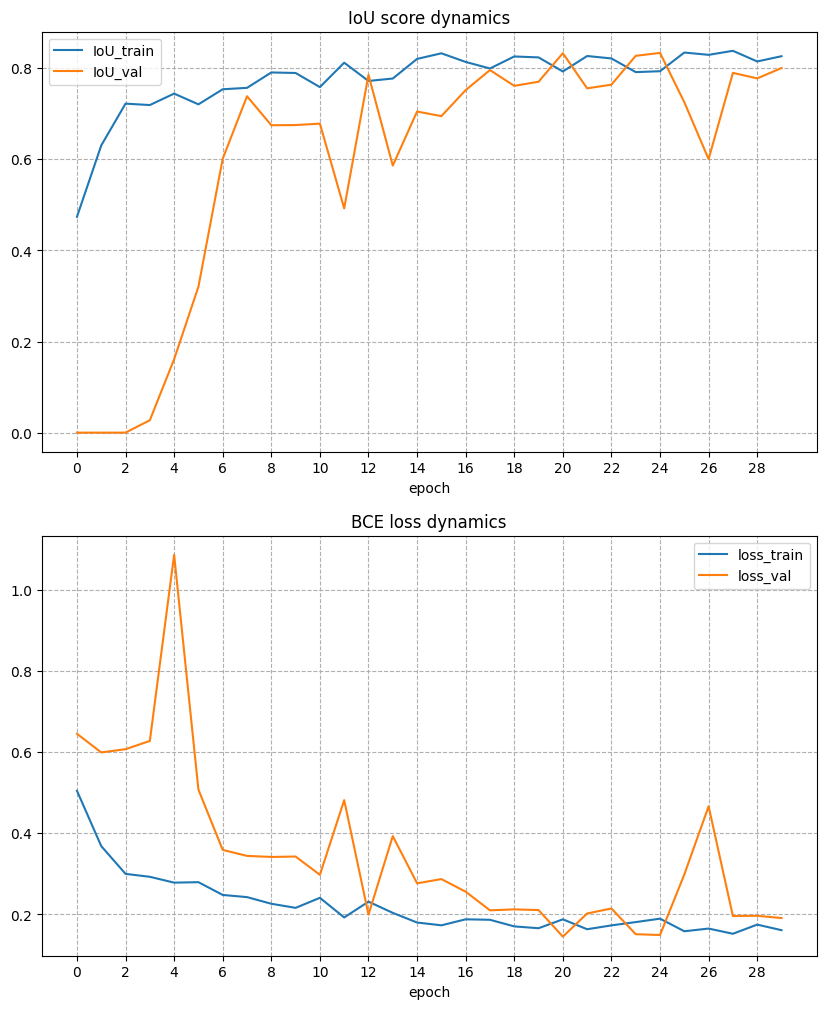

In [ ]:
plot_statistics(num_epochs, 'BCE', statistics_unet)

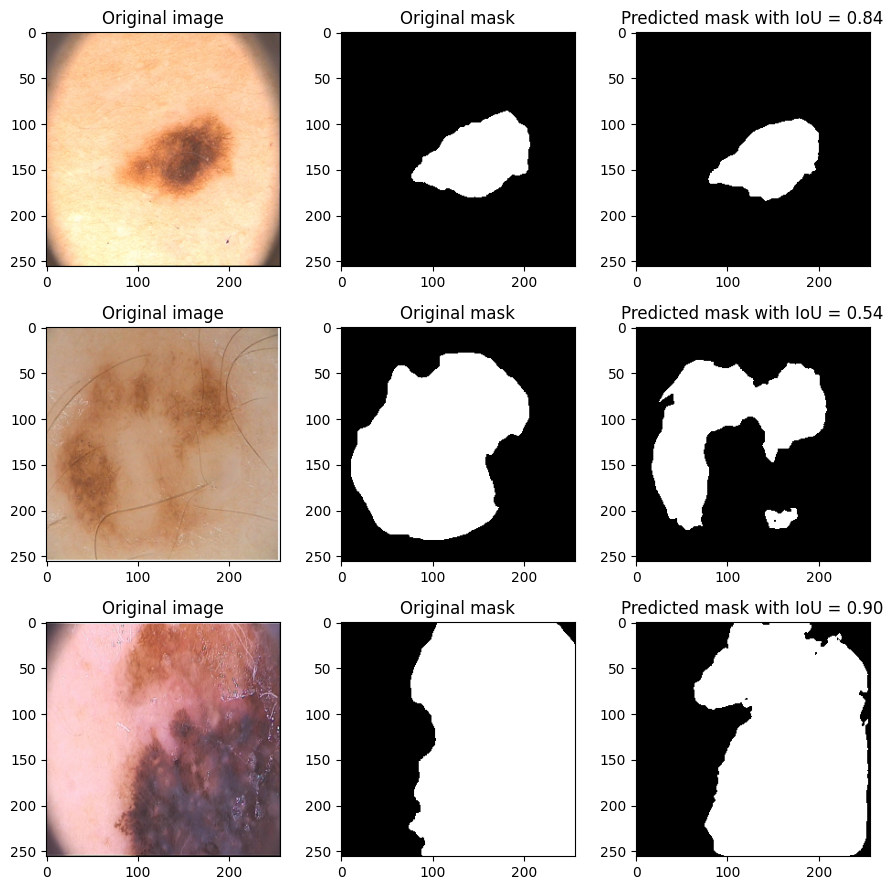

In [ ]:
best_checkpoint_path = '/content/checkpoints_unet/IoU_score'
best_checkpoint_name = 'epoch_20_best_val_loss.pt'
metric_test_unet = test(model_unet, test_dataloader, device, best_checkpoint_path, best_checkpoint_name)

In [ ]:
print(f'Best Unet IoU score on test: {metric_test_unet:.2f}')

Best Unet IoU score on test: 0.81


In [ ]:
!mkdir /content/checkpoints_unet/dice_loss

In [ ]:
# dice loss
model_unet = UNet().to(device)

optimizer = torch.optim.Adam(model_unet.parameters(), lr=1e-3)
criterion = DiceLoss(mode='binary')

checkpoint_path = '/content/checkpoints_unet'

In [ ]:
num_epochs = 30
best_unet, statistics_unet_dice = train(model_unet, num_epochs, train_dataloader, valid_dataloader, \
                                       optimizer, criterion, 'dice_loss', device, checkpoint_path)

  0%|          | 0/30 [00:00<?, ?it/s]


Epoch: 1


  0%|          | 0/4 [00:00<?, ?it/s]


Train IoU: 0.5065630972385406


  0%|          | 0/2 [00:00<?, ?it/s]

...


Val IoU: 0.720622181892395

Epoch: 30


  0%|          | 0/4 [00:00<?, ?it/s]


Train IoU: 0.8292257785797119


  0%|          | 0/2 [00:00<?, ?it/s]


Val IoU: 0.6358362436294556


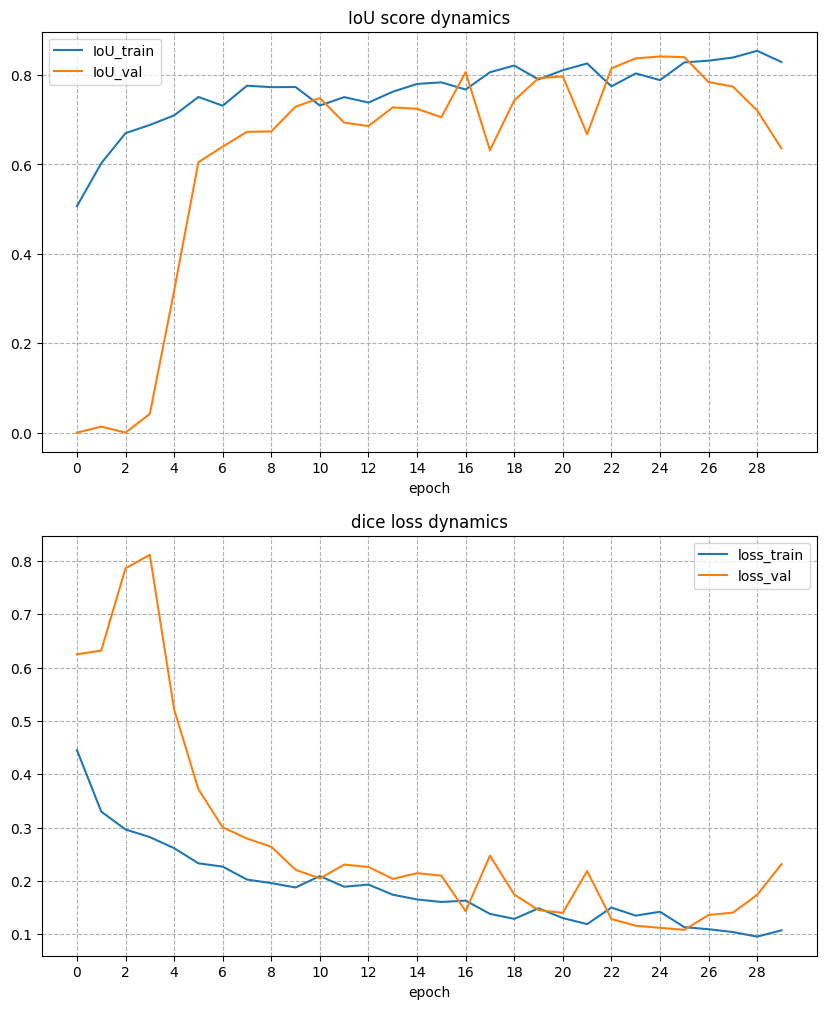

In [ ]:
plot_statistics(num_epochs, 'dice', statistics_unet_dice)

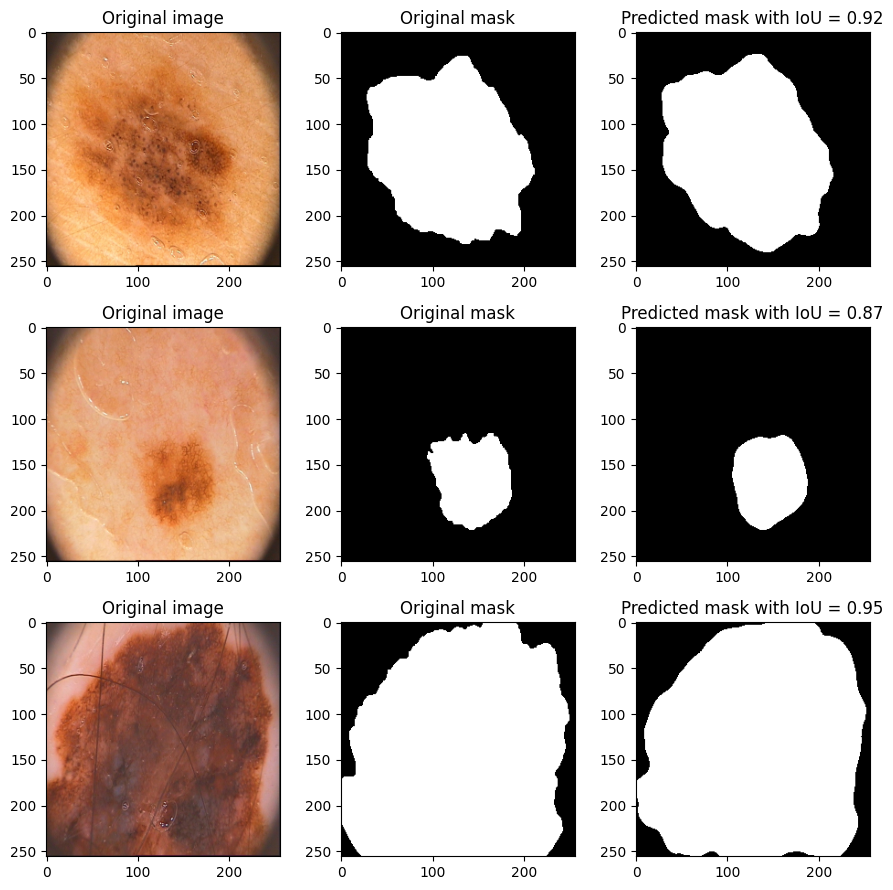

In [ ]:
best_checkpoint_path = '/content/checkpoints_unet/dice_loss'
best_checkpoint_name = 'epoch_25_best_val_loss.pt'
metric_test_unet = test(model_unet, test_dataloader, device, best_checkpoint_path, best_checkpoint_name)

In [ ]:
print(f'Best Unet with dice loss IoU score on test: {metric_test_unet:.2f}')

Best Unet with dice loss IoU score on test: 0.84


In [ ]:
!mkdir /content/checkpoints_unet/focal_loss

In [ ]:
# focal loss
model_unet = UNet().to(device)

optimizer = torch.optim.Adam(model_unet.parameters(), lr=1e-3)
criterion = lambda logits, labels: sigmoid_focal_loss(
    logits, labels, reduction='mean'
)

checkpoint_path = '/content/checkpoints_unet'

In [ ]:
num_epochs = 30
best_unet, statistics_unet_focal = train(model_unet, num_epochs, train_dataloader, valid_dataloader, \
                                       optimizer, criterion, 'focal_loss', device, checkpoint_path)

  0%|          | 0/30 [00:00<?, ?it/s]


Epoch: 1


  0%|          | 0/4 [00:00<?, ?it/s]


Train IoU: 0.3900313377380371


  0%|          | 0/2 [00:00<?, ?it/s]

...


Val IoU: 0.7418404519557953

Epoch: 30


  0%|          | 0/4 [00:00<?, ?it/s]


Train IoU: 0.8211297988891602


  0%|          | 0/2 [00:00<?, ?it/s]


Val IoU: 0.8375276625156403


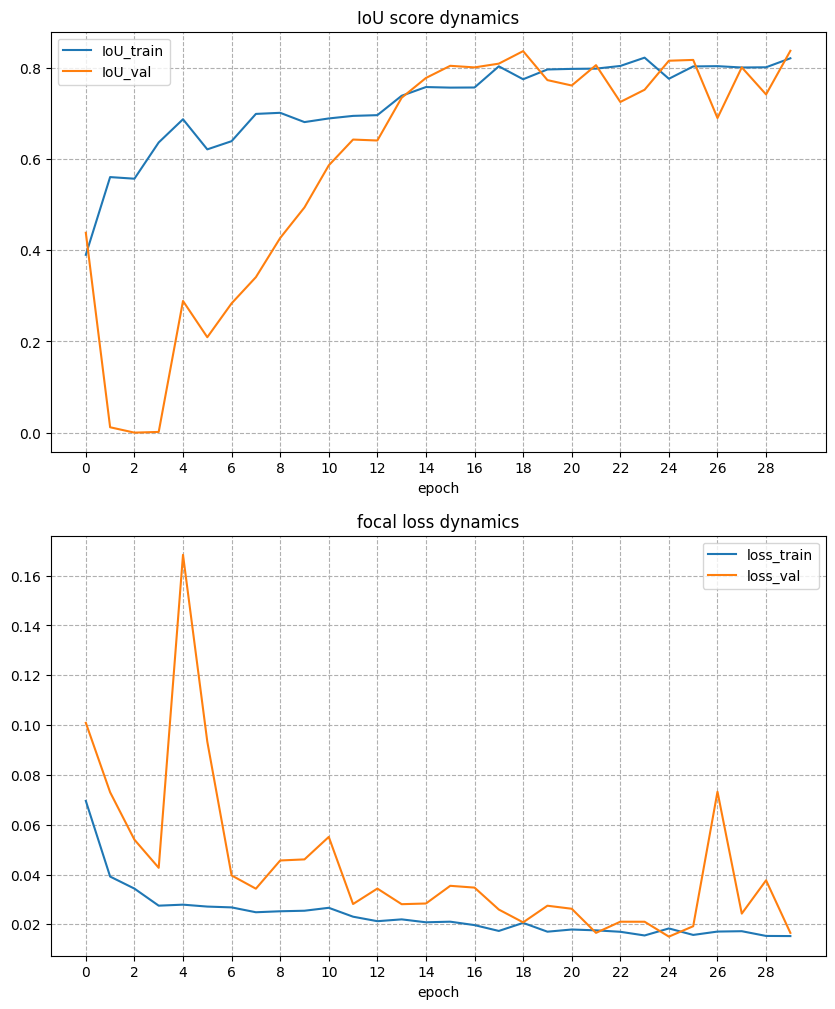

In [ ]:
plot_statistics(num_epochs, 'focal', statistics_unet_focal)

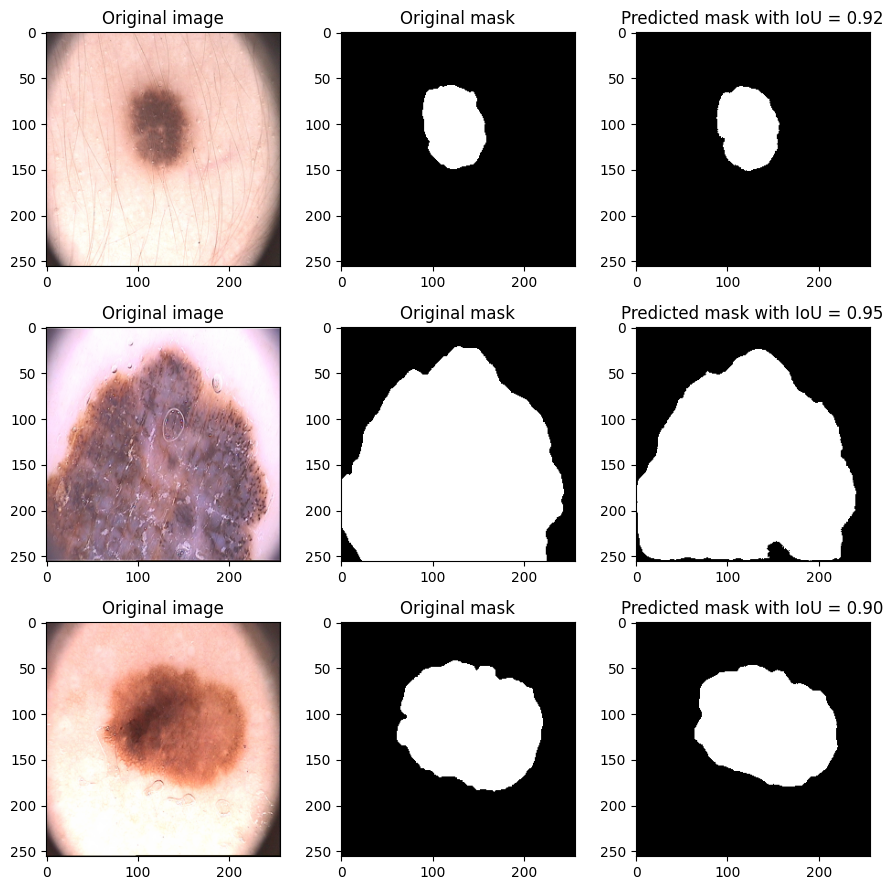

In [ ]:
best_checkpoint_path = '/content/checkpoints_unet/focal_loss'
best_checkpoint_name = 'epoch_24_best_val_loss.pt'
metric_test_unet = test(model_unet, test_dataloader, device, best_checkpoint_path, best_checkpoint_name)

In [ ]:
print(f'Best Unet with focal loss IoU score on test: {metric_test_unet:.2f}')

Best Unet with focal loss IoU score on test: 0.82


**Ответ:** <br>
1. Лучшие значения по метрике дает модель Unet. Самое лучшее качество на тесте удалось достичь на Unet с dice лоссом.
2. Лучшие значения по лоссам дает Unet, т.к. на ней не было сильных скачков лосса на валидации в начале обучения. К концу обучения у обеих моделей лосс становится +- одинаковый (в окрестности нуля).
3. Обе модели обучались +- одинаково по времени (около 3-х минут), но SegNet чуть быстрее.
4. В целом, Unet предсказывает точнее и в предсказанных ей масках довольно четкие границы без шумов.